<a href="https://colab.research.google.com/github/huynhtamtri2006-gif/TH---MACHINE_LEARNING/blob/main/tuan_2/B%C3%80I_T%E1%BA%ACP_2_BU%E1%BB%94I_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Khai báo thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# **Tải và khám phá dữ liệu Boston Housing**

In [2]:
#Đọc dữ liệu
boston = fetch_openml(
    name='boston',
    version=1,
    as_frame=True
)
X = boston.data.astype(float)
y = boston.target.astype(float)

df = X.copy()
df['MEDV'] = y

print("Kích thước dữ liệu:", df.shape)
print("Số lượng đặc trưng:", X.shape[1])
print("Số lượng mẫu:", X.shape[0])

display(df.head(10))

Kích thước dữ liệu: (506, 14)
Số lượng đặc trưng: 13
Số lượng mẫu: 506


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2
5,0.02985,0.0,2.18,0.0,0.458,6.430,58.7,6.0622,3.0,222.0,18.7,394.12,5.21,28.7
6,0.08829,12.5,7.87,0.0,0.524,6.012,66.6,5.5605,5.0,311.0,15.2,395.60,12.43,22.9
7,0.14455,12.5,7.87,0.0,0.524,6.172,96.1,5.9505,5.0,311.0,15.2,396.90,19.15,27.1
8,0.21124,12.5,7.87,0.0,0.524,5.631,100.0,6.0821,5.0,311.0,15.2,386.63,29.93,16.5
9,0.17004,12.5,7.87,0.0,0.524,6.004,85.9,6.5921,5.0,311.0,15.2,386.71,17.10,18.9


In [4]:
#Kiểm tra dữ liệu
print("Thông Tin dữ liệu:")
df.info()

print("\n Kiểm tra giá trị thiếu:")
print(df.isnull().sum())

print("\n Thông tin mô tả:")
display(df.describe())

Thông Tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    float64
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    float64
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(14)
memory usage: 55.5 KB

 Kiểm tra giá trị thiếu:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

 Thô

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


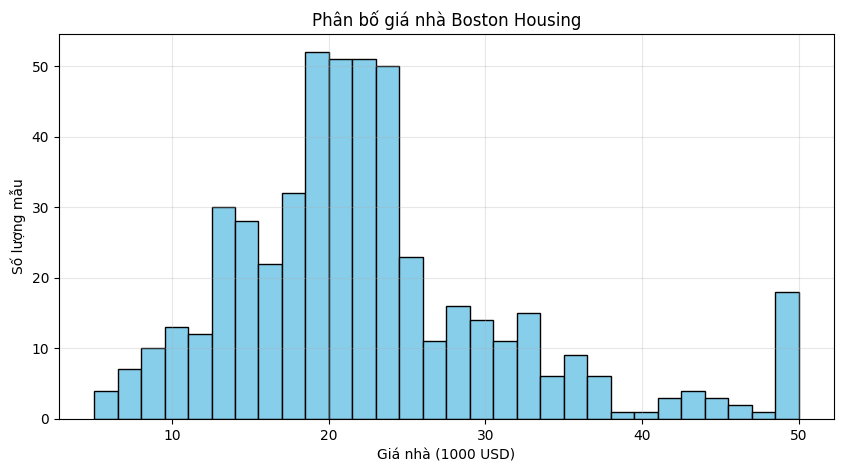

In [5]:
#Vẽ biểu đồ phân bố giá nhà
plt.figure(figsize=(10, 5))

plt.hist(
    y,
    bins=30,
    color='skyblue',
    edgecolor='black'
)

plt.xlabel('Giá nhà (1000 USD)')
plt.ylabel('Số lượng mẫu')
plt.title('Phân bố giá nhà Boston Housing')
plt.grid(alpha=0.3)
plt.show()

In [6]:
#Phân chia tập dữ liệu huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (404, 13)
X_test: (102, 13)
y_train: (404,)
y_test: (102,)


# **Chuẩn hóa dữ liệu đầu vào**

In [7]:
#Sử dụng StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dữ liệu trước chuẩn hóa:")
display(X_train.head())

print("\nDữ liệu sau chuẩn hóa:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).head())


Dữ liệu trước chuẩn hóa:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
477,15.02340,0.0,18.10,0.0,0.6140,5.304,97.3,2.1007,24.0,666.0,20.2,349.48,24.91
15,0.62739,0.0,8.14,0.0,0.5380,5.834,56.5,4.4986,4.0,307.0,21.0,395.62,8.47
332,0.03466,35.0,6.06,0.0,0.4379,6.031,23.3,6.6407,1.0,304.0,16.9,362.25,7.83
423,7.05042,0.0,18.10,0.0,0.6140,6.103,85.1,2.0218,24.0,666.0,20.2,2.52,23.29
19,0.72580,0.0,8.14,0.0,0.5380,5.727,69.5,3.7965,4.0,307.0,21.0,390.95,11.28



Dữ liệu sau chuẩn hóa:


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,1.287702,-0.500320,1.033237,-0.278089,0.489252,-1.428069,1.028015,-0.802173,1.706891,1.578434,0.845343,-0.074337,1.753505
1,-0.336384,-0.500320,-0.413160,-0.278089,-0.157233,-0.680087,-0.431199,0.324349,-0.624360,-0.584648,1.204741,0.430184,-0.561474
2,-0.403253,1.013271,-0.715218,-0.278089,-1.008723,-0.402063,-1.618599,1.330697,-0.974048,-0.602724,-0.637176,0.065297,-0.651595
3,0.388230,-0.500320,1.033237,-0.278089,0.489252,-0.300450,0.591681,-0.839240,1.706891,1.578434,0.845343,-3.868193,1.525387
4,-0.325282,-0.500320,-0.413160,-0.278089,-0.157233,-0.831094,0.033747,-0.005494,-0.624360,-0.584648,1.204741,0.379119,-0.165787


In [8]:
#Kiểm chứng kết quả chuẩn hóa
df_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X.columns
)

df_check = pd.DataFrame({
    'Mean': df_scaled.mean(),
    'Standard Deviation': df_scaled.std(ddof=0)
})

display(df_check.round(6))

,Mean,Standard Deviation
CRIM,-0.0,1.0
ZN,0.0,1.0
INDUS,-0.0,1.0
CHAS,0.0,1.0
NOX,-0.0,1.0
RM,-0.0,1.0
AGE,-0.0,1.0
DIS,0.0,1.0
RAD,-0.0,1.0
TAX,-0.0,1.0


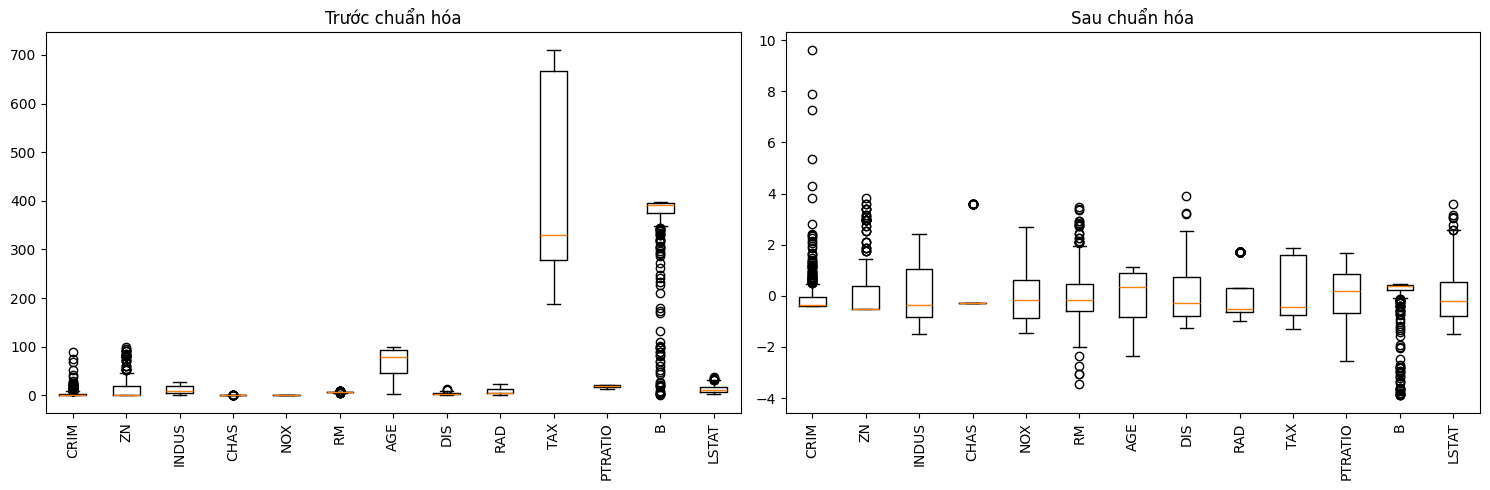

In [9]:
#Vẽ biểu đồ trước và sau chuẩn hóa
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.boxplot(X_train.values)
plt.xticks(
    range(1, len(X.columns) + 1),
    X.columns,
    rotation=90
)
plt.title('Trước chuẩn hóa')

plt.subplot(1, 2, 2)
plt.boxplot(X_train_scaled)
plt.xticks(
    range(1, len(X.columns) + 1),
    X.columns,
    rotation=90
)
plt.title('Sau chuẩn hóa')

plt.tight_layout()
plt.show()

# **Xây dựng mô hình KNN Regressor**

In [10]:
#Thử nghiệm với K = 3
knn = KNeighborsRegressor(
    n_neighbors=3,
    metric='euclidean'
)

knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("10 giá trị thực tế đầu tiên:")
print(y_test.values[:10])

print("\n10 giá trị dự đoán đầu tiên:")
print(y_pred[:10])

10 giá trị thực tế đầu tiên:
[23.6 32.4 13.6 22.8 16.1 20.  17.8 14.  19.6 16.8]

10 giá trị dự đoán đầu tiên:
[28.2        33.83333333 17.7        23.7        17.8        22.9
 19.5        16.4        21.76666667 19.96666667]


In [11]:
#So sánh giá thực tế và giá dự đoán
df_predict = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Error': y_test.values - y_pred
})

display(df_predict.head(10))

,Actual,Predicted,Error
0,23.6,28.200000,-4.600000
1,32.4,33.833333,-1.433333
2,13.6,17.700000,-4.100000
3,22.8,23.700000,-0.900000
4,16.1,17.800000,-1.700000
5,20.0,22.900000,-2.900000
6,17.8,19.500000,-1.700000
7,14.0,16.400000,-2.400000
8,19.6,21.766667,-2.166667
9,16.8,19.966667,-3.166667


# **Tính các chỉ số đánh giá mô hình**

In [12]:
#Tính MSE và R² cho K = 3
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("K = 3")
print(f"MSE: {mse:.4f}")
print(f"R2 Score: {r2:.4f}")

K = 3
MSE: 19.4043
R2 Score: 0.7354


In [13]:
#Thực nghiệm với K = 3, 5, 7, 9
k_values = [3, 5, 7, 9]

results = []
predictions = {}

for k in k_values:

    knn = KNeighborsRegressor(
        n_neighbors=k,
        metric='euclidean'
    )

    knn.fit(X_train_scaled, y_train)

    y_pred = knn.predict(X_test_scaled)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    predictions[k] = y_pred

    results.append({
        'K': k,
        'MSE': mse,
        'R2 Score': r2
    })

df_results = pd.DataFrame(results)

display(df_results.round(4))

,K,MSE,R2 Score
0,3,19.4043,0.7354
1,5,20.6055,0.7190
2,7,23.4155,0.6807
3,9,24.0094,0.6726


# **Vẽ biểu đồ so sánh kết quả**

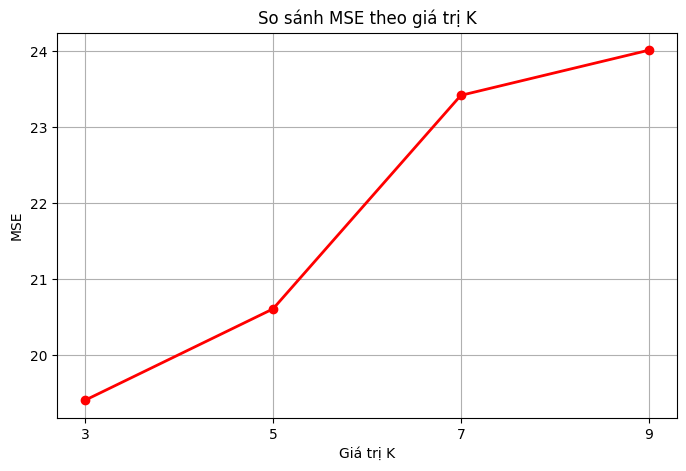

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    df_results['K'],
    df_results['MSE'],
    marker='o',
    color='red',
    linewidth=2
)

plt.xlabel('Giá trị K')
plt.ylabel('MSE')
plt.title('So sánh MSE theo giá trị K')
plt.xticks(k_values)
plt.grid()
plt.show()

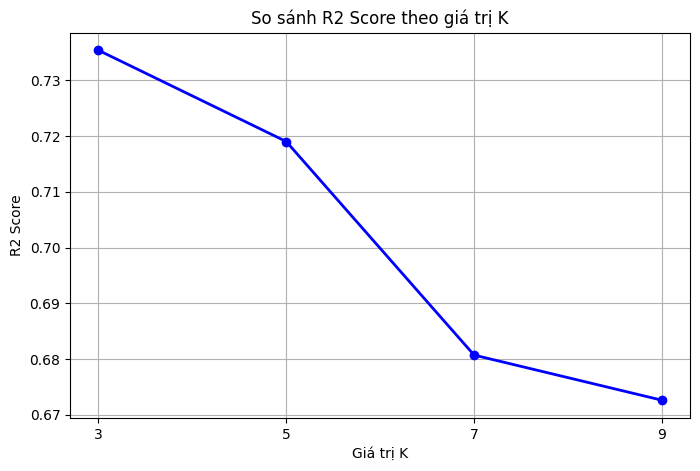

In [15]:
#Biểu đồ R² Score theo từng giá trị K
plt.figure(figsize=(8, 5))

plt.plot(
    df_results['K'],
    df_results['R2 Score'],
    marker='o',
    color='blue',
    linewidth=2
)

plt.xlabel('Giá trị K')
plt.ylabel('R2 Score')
plt.title('So sánh R2 Score theo giá trị K')
plt.xticks(k_values)
plt.grid()
plt.show()

In [16]:
#Xác định giá trị K tốt nhất trong thực nghiệm
best_result = df_results.loc[
    df_results['MSE'].idxmin()
]

best_k = int(best_result['K'])

print("K tốt nhất:", best_k)
print(f"MSE thấp nhất: {best_result['MSE']:.4f}")
print(f"R2 Score: {best_result['R2 Score']:.4f}")

K tốt nhất: 3
MSE thấp nhất: 19.4043
R2 Score: 0.7354


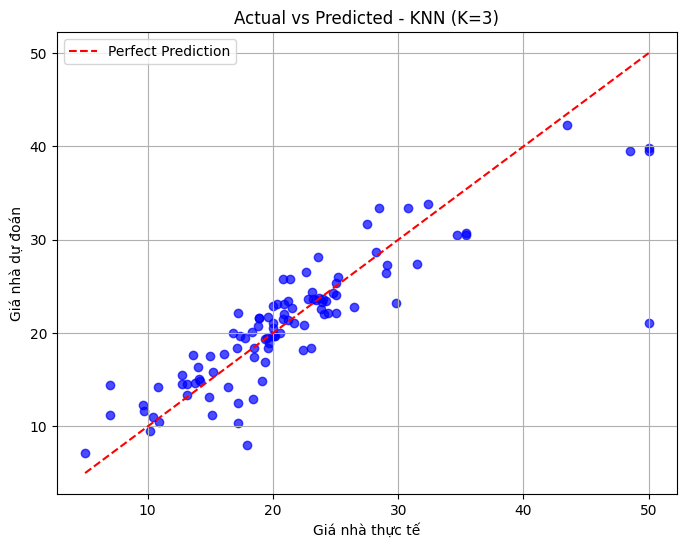

In [17]:
#Vẽ biểu đồ giá thực tế và giá dự đoán
y_pred_best = predictions[best_k]

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_best,
    color='blue',
    alpha=0.7
)

min_value = min(y_test.min(), y_pred_best.min())
max_value = max(y_test.max(), y_pred_best.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label='Perfect Prediction'
)

plt.xlabel('Giá nhà thực tế')
plt.ylabel('Giá nhà dự đoán')
plt.title(f'Actual vs Predicted - KNN (K={best_k})')
plt.legend()
plt.grid()
plt.show()